# A teaching extract is not a census

**Spatial methods · 15–25 minutes · old edition**

The old repository's distinct revised learning edition describes local teaching extracts and a Pyodide-safe spatial helper module.

**Learning question:** Can an uneven teaching extract change a summary of the same invented cells?

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Compare the complete eight-cell fictional fixture with an uneven four-cell extract. Print group coverage before comparing means. Here the full fixture is known only because we invented it; actual teaching extracts do not supply a population census. These fixtures have no missing values. Calculations require complete finite numeric values; define a missing-data rule before introducing missing data.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


All cells are invented: [('L1', 'low', 1), ('L2', 'low', 2), ('L3', 'low', 2), ('L4', 'low', 3), ('H1', 'high', 7), ('H2', 'high', 8), ('H3', 'high', 6), ('H4', 'high', 7)]
Extract IDs: ['H1', 'H2', 'H3', 'L1'] ; group coverage: {'low': {'full': 4, 'extract': 1}, 'high': {'full': 4, 'extract': 3}}
Synthetic extract selection changes the mean | arbitrary cell value: {'complete invented fixture': 4.5, 'uneven teaching extract': 5.5}


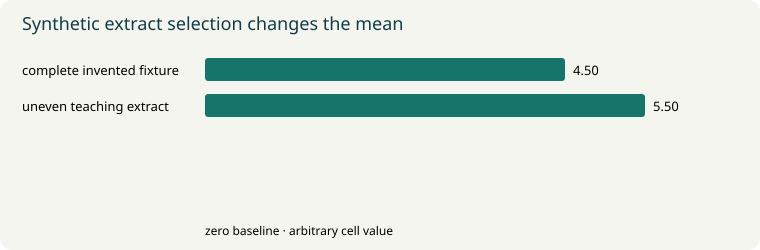

In [2]:
cells = [('L1','low',1), ('L2','low',2), ('L3','low',2), ('L4','low',3), ('H1','high',7), ('H2','high',8), ('H3','high',6), ('H4','high',7)]
selected_ids = {'L1', 'H1', 'H2', 'H3'}
extract = [row for row in cells if row[0] in selected_ids]
coverage = {group:{'full':sum(row[1]==group for row in cells), 'extract':sum(row[1]==group for row in extract)} for group in ['low','high']}
means = {'complete invented fixture':sum(row[2] for row in cells)/len(cells), 'uneven teaching extract':sum(row[2] for row in extract)/len(extract)}
print('All cells are invented:', cells)
print('Extract IDs:', sorted(selected_ids), '; group coverage:', coverage)
bars(means, 'Synthetic extract selection changes the mean', 'arbitrary cell value')


## Interpret the result

The full invented mean is 4.5; the extract mean is 5.5. Both group imbalance and within-group selection matter: three of four selected cells come from the high group, whose full mean is 7, but the selected low cell L1=1 is below its group's full mean of 2. Group imbalance alone, retaining those group means, would give 5.75; selecting L1 lowers that to 5.5. The selected high cells still average 7. A compact extract can teach a method without representing a population. Completeness, selection and original units must be checked before transferring a conclusion.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Select two cells from each group and compare again. Record the selection rule, missing groups and original source terms alongside any future real teaching extract.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-Geospatial-Analyses-and-Maps-old](https://github.com/jltobias/JupyterLite-Geospatial-Analyses-and-Maps-old).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-Geospatial-Analyses-and-Maps-old/blob/f712588e27b1eba24c71b4334975ea474ece9f8d/README.md); inspected 2026-11-01, commit `f712588e27b1`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

Keep this -old repository separate from Geospatial-Analyses-and-Maps, its -revised variant, and Maps-and-Spatial-Analyses. Although its README calls itself a revised learning edition, the repository name remains -old. It describes Meuse, SIDS-style, taxi, housing, Iris, earthquake and other teaching extracts, but this atlas copies none of those datasets or helpers and makes no rights claim about them. No exact hosted launch URL is documented.

No exact published launch URL is documented in this README. Use the repository source; hosted availability is unverified.

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. Continue with the reviewed README's local JupyterLite build, including notebooks, data and spatial_lite.py. It documents the Python (Pyodide) kernel and numpy/pandas/matplotlib workflows that avoid compiled GIS stacks. Review each teaching extract's provenance and terms before reuse; no hosted launch URL is documented. [Reviewed source README](https://github.com/jltobias/JupyterLite-Geospatial-Analyses-and-Maps-old/blob/f712588e27b1eba24c71b4334975ea474ece9f8d/README.md).

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
